In [1]:
from pathlib import Path

from datautils.data import read
from datautils.query import CatalogueQuery
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

In [2]:
catalogues = [
    Path("data/catalogues/SHRU921_Tetra_FileInfo.csv"),
    Path("data/catalogues/SHRU905_VLA1_FileInfo.csv"),
    Path("data/catalogues/SHRU920_VLA2_FileInfo.csv"),
]
arrays = ["Tetra", "VLA1", "VLA2"]

tstarts = [
    "2023-07-09T10:29:59.5",
    "2023-07-09T10:30:00.5",
    "2023-07-09T10:30:04",
]
tends = [
    "2023-07-09T10:30:01.5",
    "2023-07-09T10:30:02.5",
    "2023-07-09T10:30:06",
]
time_starts = [np.datetime64(t, "us") for t in tstarts]
time_ends = [np.datetime64(t, "us") for t in tends]
channels = [0, 1, 2, 3]

# c = 1.500
# r = np.array([1.0, 2.5, 7.5])
# t = r / c
# print(np.diff(t * fs))
# print(np.diff(t * fs) / fs)

In [58]:
data = []
for cat, time_start, time_end in zip(catalogues, time_starts, time_ends):

    cat_query = CatalogueQuery(
        catalogue=cat,
        destination=None,
        time_start=time_start,
        time_end=time_end,
        channels=channels,
    )
    data.append(read(cat_query))

fs = data[0].stats.sampling_rate

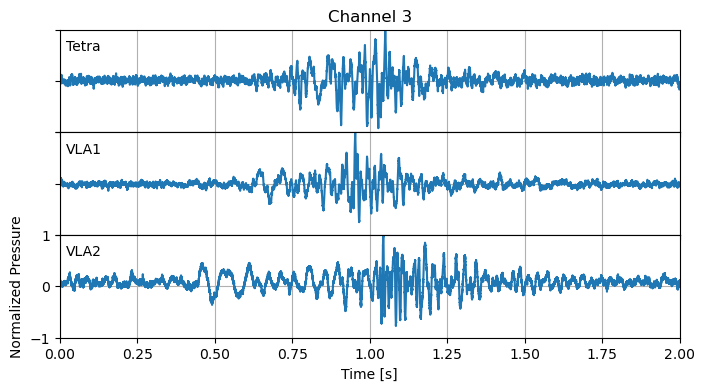

In [85]:
chan = 3

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(8, 4), gridspec_kw={"hspace": 0.0})

for i, d in enumerate(data):
    ax = axs[i]
    sig = d.waveform[:, chan]
    tvec = (d.time_vector - d.time_vector[0]) / np.timedelta64(1, "s")
    ax.plot(tvec, sig / max(abs(sig)), label=arrays[i])
    axs[i].set_xlim(tvec[0], tvec[-1])
    axs[i].set_ylim(-1, 1)
    ax.text(0.01, 0.8, f"{arrays[i]}", horizontalalignment="left", transform=ax.transAxes)
    ax.grid(True)

    if i == 0:
        ax.set_title(f"Channel {chan}")
    
    if i == 2:
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Normalized Pressure")
    else:
        ax.set_xticklabels([])
        ax.set_yticklabels([])

fig.savefig(f"reports/dispersion_stack/pressure_waveforms_ch{chan}.png", dpi=300, bbox_inches="tight")

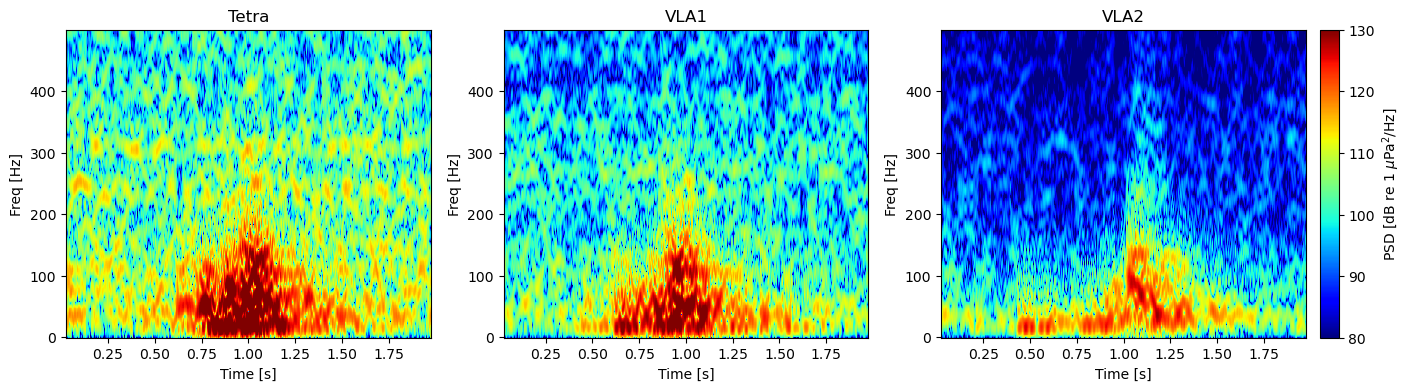

In [84]:
chan = 3

fmin = 0
fmax = 500

vmin = 80
vmax = 130

window_sec = 0.05
nperseg = int(window_sec * fs)
nfft = nperseg * 16 
overlap = 0.99

fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
for title, ax, d in zip(arrays, axs, data):
    f, t, Sxx = signal.spectrogram(
        d.waveform[:, chan], fs, nperseg=nperseg, nfft=nfft, noverlap=int(overlap * nperseg)
    )
    if fmin and fmax:
        Sxx = Sxx[(f >= fmin) & (f <= fmax), :]
        f = f[(f >= fmin) & (f <= fmax)]
    elif fmin:
        Sxx = Sxx[f >= fmin, :]
        f = f[f >= fmin]
    elif fmax:
        Sxx = Sxx[f <= fmax, :]
        f = f[f <= fmax]

    im = ax.pcolormesh(t, f, 10 * np.log10(Sxx), cmap="jet", vmin=vmin, vmax=vmax)
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Freq [Hz]")
    ax.set_title(title)

cax = ax.inset_axes([1.04, 0.0, 0.05, 1.0])
fig.colorbar(im, ax=ax, cax=cax, label="PSD [dB re 1 $\\mu$Pa$^2$/Hz]")
fig.savefig(f"reports/dispersion_spectrogram/channel{chan}.png", dpi=300, bbox_inches="tight")